# GAT-GRU v02 — graph ablation

So sánh GRU node-only, static GAT với topology đúng/sai và dynamic GAT-GRU với cùng node features, config và seeds. Chỉ dùng train/validation.

In [1]:
import sys
from pathlib import Path
import torch

ROOT = Path.cwd().resolve()
while not (ROOT / 'modeling-common').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'modeling-common'))
import forecast_ablation as fa

ctx = fa.load_context(ROOT)
selection = fa.load_selection_contract(ROOT / 'configs' / 'gatgru' / 'feature_contract_v01.json')
cfg = fa.load_baseline_config(ctx)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
# Preserve the original v02 outputs; this extended control study has its own directory.
OUT = ROOT / 'artifacts' / 'gatgru' / 'v02_graph_controls'
# The variant factory includes four deterministic topology shuffles (one existing plus three new),
# self-loop-only graph, and a random graph at matched edge density. Validation only.
summary = fa.run_fixed_variants(
    ctx, 'v02_graph_controls', OUT,
    fa.graph_variants(cfg, selection['node_features']),
    seeds=(0, 1, 2, 3, 4), device=DEVICE, score_weights=fa.BASELINE_SCORE_WEIGHTS,
    parent_version='v02_graph_ablation',
)
display(summary)

,variant,model_kind,node_features,edge_features,edge_control,topology_control,n_seeds,primary_score_mean,primary_score_std,cpu_weighted_diagnostic_mean,...,cpu_cores_mae_macro_mean,cpu_cores_mae_macro_std,train_seconds_mean,train_seconds_std,early_stop_val_mae_mean,early_stop_val_mae_std,n_params_mean,n_params_std,epochs_trained_mean,epochs_trained_std
3,dynamic_all_edges,gatgru,"[rps_in, rps_in_delta, rps_per_replica, latenc...","[call_rate, call_ratio, edge_latency_p95_ms]",real,real,5,0.113994,0.001107,0.106535,...,0.013603,0.000213,727.227808,142.900378,0.113970,0.001106,121560.0,0.0,27.4,1.816590
4,static_gat_shuffled_topology_seed_101,gatgru,"[rps_in, rps_in_delta, rps_per_replica, latenc...",[],real,node_permutation_101,5,0.114035,0.000560,0.106558,...,0.013578,0.000158,508.433452,48.499137,0.114013,0.000560,121528.0,0.0,26.2,1.303840
6,static_gat_shuffled_topology_seed_303,gatgru,"[rps_in, rps_in_delta, rps_per_replica, latenc...",[],real,node_permutation_303,5,0.114091,0.000805,0.106821,...,0.013665,0.000128,599.230779,126.654070,0.114069,0.000805,121528.0,0.0,29.2,4.764452
1,static_gat_shuffled_topology,gatgru,"[rps_in, rps_in_delta, rps_per_replica, latenc...",[],real,node_permutation,5,0.114340,0.000671,0.106702,...,0.013536,0.000195,687.021206,112.067606,0.114317,0.000672,121528.0,0.0,30.4,3.911521
2,static_gat,gatgru,"[rps_in, rps_in_delta, rps_per_replica, latenc...",[],real,real,5,0.114503,0.000825,0.107162,...,0.013711,0.000273,843.802202,307.745329,0.114481,0.000825,121528.0,0.0,27.6,2.190890
5,static_gat_shuffled_topology_seed_202,gatgru,"[rps_in, rps_in_delta, rps_per_replica, latenc...",[],real,node_permutation_202,5,0.114830,0.000643,0.107232,...,0.013668,0.000184,490.869760,101.346358,0.114808,0.000643,121528.0,0.0,26.8,5.310367
7,static_gat_full_directed,gatgru,"[rps_in, rps_in_delta, rps_per_replica, latenc...",[],real,full_directed,5,0.114959,0.000408,0.107308,...,0.013623,0.000117,577.431634,81.438697,0.114935,0.000406,121528.0,0.0,27.2,3.962323
9,static_gat_random_same_density,gatgru,"[rps_in, rps_in_delta, rps_per_replica, latenc...",[],real,random_same_density,5,0.115609,0.000482,0.108123,...,0.013778,0.000103,682.192584,101.868494,0.115587,0.000482,121528.0,0.0,32.4,4.979960
8,static_gat_self_loops_only,gatgru,"[rps_in, rps_in_delta, rps_per_replica, latenc...",[],real,self_loops_only,5,0.118082,0.000484,0.110570,...,0.014146,0.000107,650.946850,66.957776,0.118059,0.000485,121528.0,0.0,30.6,3.361547
0,gru_node_only,gru_node_only,"[rps_in, rps_in_delta, rps_per_replica, latenc...",[],real,real,5,0.118488,0.000528,0.110963,...,0.014178,0.000135,580.702621,132.883788,0.118465,0.000527,121016.0,0.0,29.6,5.594640


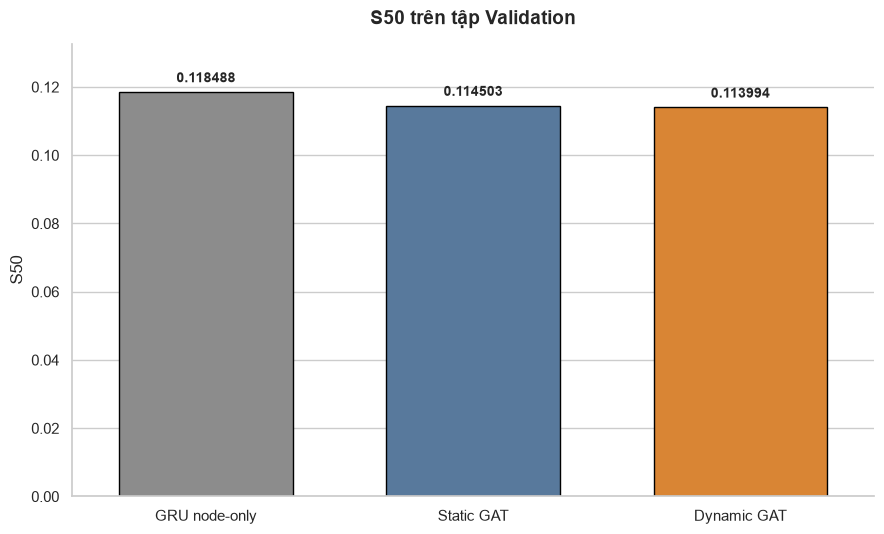

,Model,S50
0,GRU node-only,0.118488
1,Static GAT,0.114503
2,Dynamic GAT,0.113994


In [8]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = ROOT
RESULT_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "gatgru"
    / "v02_graph_controls"
)

summary = pd.read_csv(RESULT_DIR / "variant_summary.csv")

variant_order = [
    "gru_node_only",
    "static_gat",
    "dynamic_all_edges",
]

variant_labels = {
    "gru_node_only": "GRU node-only",
    "static_gat": "Static GAT",
    "dynamic_all_edges": "Dynamic GAT",
}

plot_df = (
    summary.loc[
        summary["variant"].isin(variant_order),
        ["variant", "primary_score_mean"],
    ]
    .set_index("variant")
    .loc[variant_order]
    .reset_index()
    .rename(columns={"primary_score_mean": "S50"})
)

plot_df["Model"] = plot_df["variant"].map(variant_labels)

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(9, 5.5))

model_order = list(variant_labels.values())
palette = {
    "GRU node-only": "#8C8C8C",
    "Static GAT": "#4C78A8",
    "Dynamic GAT": "#F58518",
}

sns.barplot(
    data=plot_df,
    x="Model",
    y="S50",
    order=model_order,
    hue="Model",
    hue_order=model_order,
    palette=palette,
    legend=False,
    errorbar=None,
    edgecolor="black",
    linewidth=1,
    width=0.65,
    ax=ax,
)

# Chỉ hiển thị giá trị S50 trung bình
for bar in ax.patches:
    height = bar.get_height()

    if height > 0:
        ax.annotate(
            f"{height:.6f}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="semibold",
        )

ax.set_title(
    "S50 trên tập Validation",
    fontsize=14,
    fontweight="bold",
    pad=14,
)
ax.set_xlabel("")
ax.set_ylabel("S50")
ax.set_ylim(0, plot_df["S50"].max() * 1.12)

ax.grid(axis="x", visible=False)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

display(plot_df[["Model", "S50"]])